# Notebook de documentacion, tratamiento datos y entrenamiento


## Equipo
- Alumno 1: Máximo Alva
- Alumno 2: Zahir Jacob

## Configuración del entorno

In [85]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [95]:
DATA_DIR = Path("./data/CelebA")
IMGS_DIR = DATA_DIR / "Img" / "img_align_celeba"
IDENTITY_PATH = DATA_DIR / "Anno" / "identity_CelebA.txt"
ATTR_PATH = DATA_DIR / "Anno" / "list_attr_celeba.txt"
BBOX_PATH = DATA_DIR / "Anno" / "list_bbox_celeba.txt"
LANDMARKS_PATH = DATA_DIR / "Anno" / "list_landmarks_align_celeba.txt"

## Elección del dataset

https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html

https://drive.google.com/drive/folders/0B7EVK8r0v71pWEZsZE9oNnFzTm8

https://www.kaggle.com/datasets/khnhhong/celeba

### Descarga

In [ ]:
# Completar descargas

### Cargar dataframes

#### Identity

In [90]:
df_identity = pd.read_csv(IDENTITY_PATH, sep=" ", header=None, names=["image_id", "identity"])
df_identity

,image_id,identity
0,000001.jpg,2880
1,000002.jpg,2937
2,000003.jpg,8692
3,000004.jpg,5805
4,000005.jpg,9295
...,...,...
202594,202595.jpg,9761
202595,202596.jpg,7192
202596,202597.jpg,9852
202597,202598.jpg,5570


#### Attr

In [98]:
df_attr = pd.read_csv(ATTR_PATH, sep=r'\s+',skiprows=1, engine='python')
df_attr.reset_index(inplace=True)
df_attr.rename(columns={df_attr.columns[0]: 'image_id'}, inplace=True)
df_attr

,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,-1,-1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
202595,202596.jpg,-1,-1,-1,-1,-1,1,1,-1,-1,...,-1,1,1,-1,-1,-1,-1,-1,-1,1
202596,202597.jpg,-1,-1,-1,-1,-1,-1,-1,-1,1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
202597,202598.jpg,-1,1,1,-1,-1,-1,1,-1,1,...,-1,1,-1,1,1,-1,1,-1,-1,1


#### Bbox

In [101]:
df_bbox = pd.read_csv(BBOX_PATH, sep=r'\s+', skiprows=1)
df_bbox.rename(columns={'x_1': 'bbox_x1', 'y_1': 'bbox_y1', 'width': 'bbox_width', 'height': 'bbox_height'}, inplace=True)
df_bbox

,image_id,bbox_x1,bbox_y1,bbox_width,bbox_height
0,000001.jpg,95,71,226,313
1,000002.jpg,72,94,221,306
2,000003.jpg,216,59,91,126
3,000004.jpg,622,257,564,781
4,000005.jpg,236,109,120,166
...,...,...,...,...,...
202594,202595.jpg,1381,91,221,306
202595,202596.jpg,137,129,114,158
202596,202597.jpg,53,76,91,126
202597,202598.jpg,195,28,91,126


#### Landmarks

In [99]:
df_landmarks = pd.read_csv(LANDMARKS_PATH, sep=r'\s+', skiprows=1)
df_landmarks.reset_index(inplace=True)
df_landmarks.rename(columns={df_landmarks.columns[0]: 'image_id'}, inplace=True)
df_landmarks

,image_id,lefteye_x,lefteye_y,righteye_x,righteye_y,nose_x,nose_y,leftmouth_x,leftmouth_y,rightmouth_x,rightmouth_y
0,000001.jpg,69,109,106,113,77,142,73,152,108,154
1,000002.jpg,69,110,107,112,81,135,70,151,108,153
2,000003.jpg,76,112,104,106,108,128,74,156,98,158
3,000004.jpg,72,113,108,108,101,138,71,155,101,151
4,000005.jpg,66,114,112,112,86,119,71,147,104,150
...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,69,111,108,111,89,140,73,151,104,153
202595,202596.jpg,67,112,110,112,85,141,66,150,110,150
202596,202597.jpg,69,111,107,111,92,137,68,151,109,153
202597,202598.jpg,69,111,108,111,90,137,71,153,106,151


### Unir dataframes

In [104]:
# Unificar todos los dataframes usando 'image_id' como primary key
df_celeba = df_identity.merge(df_attr, on='image_id', how='inner')
df_celeba = df_celeba.merge(df_bbox, on='image_id', how='inner')
df_celeba = df_celeba.merge(df_landmarks, on='image_id', how='inner')
df_celeba

,image_id,identity,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,...,lefteye_x,lefteye_y,righteye_x,righteye_y,nose_x,nose_y,leftmouth_x,leftmouth_y,rightmouth_x,rightmouth_y
0,000001.jpg,2880,-1,1,1,-1,-1,-1,-1,-1,...,69,109,106,113,77,142,73,152,108,154
1,000002.jpg,2937,-1,-1,-1,1,-1,-1,-1,1,...,69,110,107,112,81,135,70,151,108,153
2,000003.jpg,8692,-1,-1,-1,-1,-1,-1,1,-1,...,76,112,104,106,108,128,74,156,98,158
3,000004.jpg,5805,-1,-1,1,-1,-1,-1,-1,-1,...,72,113,108,108,101,138,71,155,101,151
4,000005.jpg,9295,-1,1,1,-1,-1,-1,1,-1,...,66,114,112,112,86,119,71,147,104,150
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,9761,-1,-1,1,-1,-1,-1,1,-1,...,69,111,108,111,89,140,73,151,104,153
202595,202596.jpg,7192,-1,-1,-1,-1,-1,1,1,-1,...,67,112,110,112,85,141,66,150,110,150
202596,202597.jpg,9852,-1,-1,-1,-1,-1,-1,-1,-1,...,69,111,107,111,92,137,68,151,109,153
202597,202598.jpg,5570,-1,1,1,-1,-1,-1,1,-1,...,69,111,108,111,90,137,71,153,106,151


### División train, test y val

## Análisis exploratorio (EDA)

In [43]:
print(f"Total de imágenes en {IMGS_DIR}: {len(list(IMGS_DIR.glob('*.jpg')))}")

Total de imágenes en data\CelebA\Img\img_align_celeba: 202599


In [ ]:
print(f"Total de imágenes indexadas por identidad: {len(df_identity)}")
print(f"Total de identidades únicas: {df_identity['identity'].nunique()}")

In [ ]:
identity_counts = df_identity["identity"].value_counts()
print(identity_counts)

identity_id
2820    35
3782    35
3227    35
3745    34
3699    34
        ..
4273     1
2708     1
8565     1
8585     1
7778     1
Name: count, Length: 10177, dtype: int64


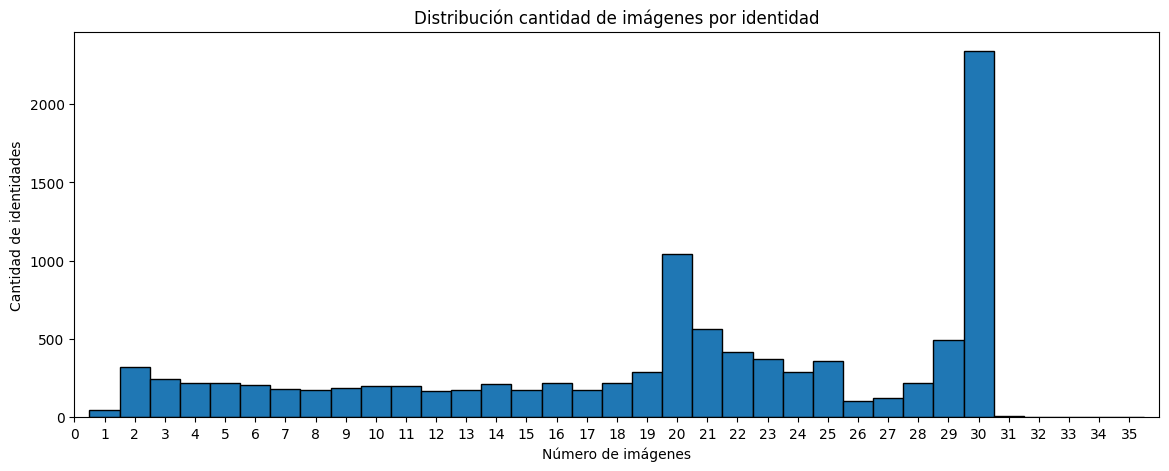

In [72]:
# Gráfico de distribución
identity_counts_max = identity_counts.max()
plt.figure(figsize=(14, 5))
bins = np.arange(1, identity_counts_max + 2) - 0.5
plt.hist(identity_counts, bins=bins, edgecolor='black')
plt.xlim(0, identity_counts_max + 1)
plt.xticks(range(0, identity_counts_max + 1))
plt.title("Distribución cantidad de imágenes por identidad")
plt.xlabel("Número de imágenes")
plt.ylabel("Cantidad de identidades")
plt.show()

In [52]:
print(identity_counts.describe())

count    10177.000000
mean        19.907537
std          8.925916
min          1.000000
25%         13.000000
50%         21.000000
75%         29.000000
max         35.000000
Name: count, dtype: float64


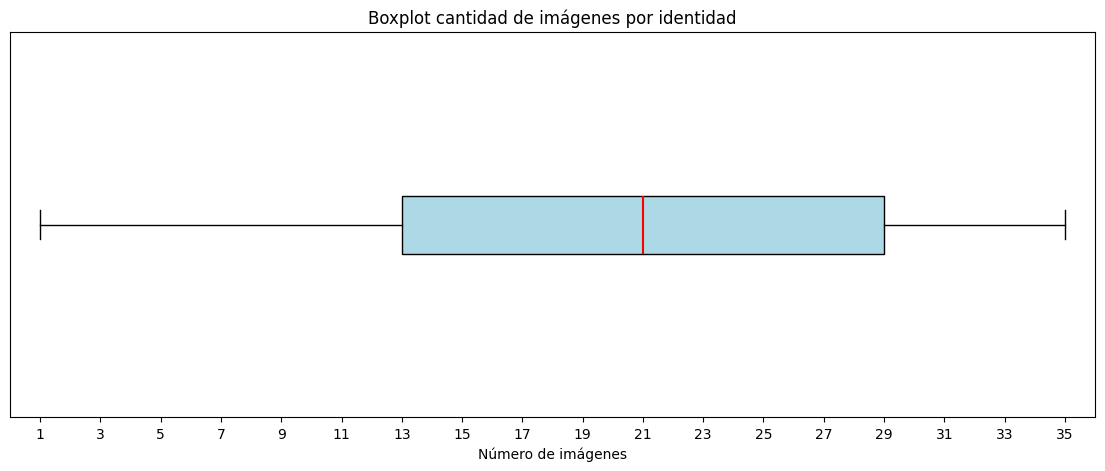

In [84]:
# Boxplot
plt.figure(figsize=(14, 5))
plt.boxplot(identity_counts, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue', color='black'), medianprops=dict(color='red', linewidth=1.5))
plt.xlim(0, identity_counts_max + 1)
plt.xticks(range(1, identity_counts_max + 1, 2))
plt.title("Boxplot cantidad de imágenes por identidad")
plt.xlabel("Número de imágenes")
plt.gca().axes.get_yaxis().set_visible(False)
plt.show()

## Control de calidad y limpieza

## Detección y alineación (normalización)

## Clustering exploratorio

## Data augmentation

## Partición de datos (splits)

## Ética, privacidad y licencias